In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
#loading the WT and AmpB bedgraphs:
wt = pd.read_csv("LmexWT.bedgraph", sep="\t", header=None, names=["chrom", "start", "end", "coverage"])
ampb = pd.read_csv("LmexAmpB.bedgraph", sep="\t", header=None, names=["chrom", "start", "end", "coverage"])

In [3]:
#add Sample labels:
wt["sample"] = "WT"
ampb["sample"] = "AmpB"

#combining the two tables:
combined = pd.concat([wt, ampb])


In [4]:
#median genome wide coverage:
print("Genome wide coverage:")
print(combined.groupby("sample")["coverage"].median())


Genome wide coverage:
sample
AmpB    3.56381
WT      3.53809
Name: coverage, dtype: float64


In [5]:
#median per chromosome:
print("Median coverage per chromosome:")
median_per_chr = combined.groupby(["sample","chrom"])["coverage"].median()
print(median_per_chr)

Median coverage per chromosome:
sample  chrom  
AmpB    LmxM.00    3.52285
        LmxM.01    2.13009
        LmxM.02    2.37587
        LmxM.03    2.25298
        LmxM.04    3.68670
                    ...   
WT      LmxM.30    6.52905
        LmxM.31    3.57456
        LmxM.32    3.61104
        LmxM.33    3.61104
        LmxM.34    3.90284
Name: coverage, Length: 70, dtype: float64


In [6]:
#variability in chromosome medians:
print("Standard deviation of median coverage per chromosome:")
std_dev = median_per_chr.groupby("sample").std()
print(std_dev)

Standard deviation of median coverage per chromosome:
sample
AmpB    0.898833
WT      0.818739
Name: coverage, dtype: float64


In [7]:
#Violin plot: coverage distribution per chromosome:
grouped_data = {}
for (sample, chrom), group in combined.groupby(["sample","chrom"]):
    key = f"{sample}_{chrom}"
    grouped_data[key] = group["coverage"].values
    
#arranging the Wt and AMPb resistant side by side    
sorted_keys = sorted(grouped_data.keys(), key=lambda x: (x.split("_")[1], x.split("_")[0]))


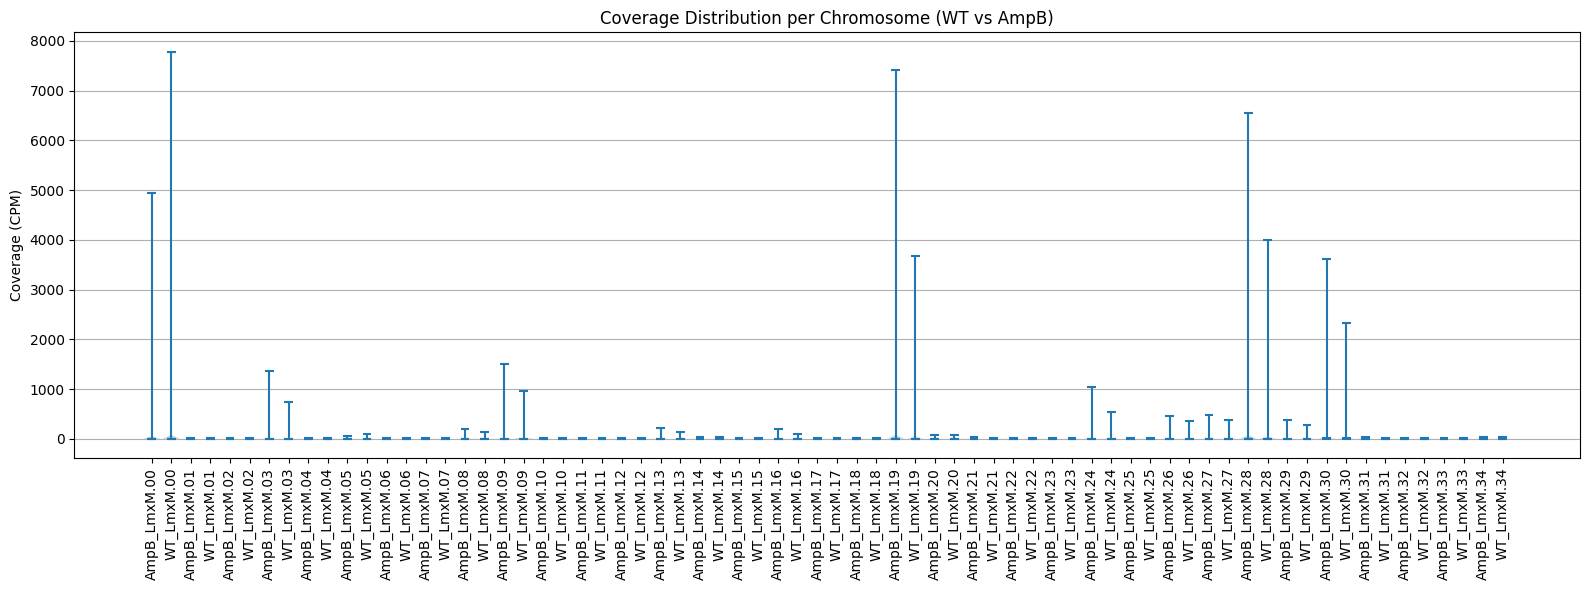

In [8]:
#plotting:
# Prepare data for violinplot
violin_data = [grouped_data[k] for k in sorted_keys]
x_labels = sorted_keys

# Plot
plt.figure(figsize=(16, 6))
plt.violinplot(violin_data, showmedians=True, widths=0.9)

# Customize x-axis
plt.xticks(ticks=range(1, len(x_labels) + 1), labels=x_labels, rotation=90)
plt.title("Coverage Distribution per Chromosome (WT vs AmpB)")
plt.ylabel("Coverage (CPM)")
plt.tight_layout()
plt.grid(axis='y')

plt.show()